# Reto TC1002B – Legibilidad de Datos para la Toma de Decisiones

## Sección 1: Título, Autor y Contexto Municipal

**Integrantes del equipo:**
- Laura Jimena Villagrán Sánchez – A01772066
- Maria Cristina Hernandez Lujano – A01771850
- Adriana Garcia – A01771682
- Alexa Olalde– A01775044

**Fuente de información seleccionada:**  
DATA MÉXICO – Evolución del Salario Promedio Mensual por Sector (IMSS, Series Trimestrales 2010-2025)  
Liga de descarga: https://www.economia.gob.mx/datamexico/

**Condiciones de selección:**
- **Sector:** Servicios Educativos (Sector 61)
- **Nivel:** Nacional
- **Período:** 2010 – 2025 (trimestral)
- **Variable principal:** Salario Mensual Promedio (pesos corrientes)

**Problema principal declarado:** `infraestructura / finanzas`  
El salario promedio del sector educativo es un indicador clave para entender la capacidad adquisitiva de servidores públicos y la inversión en capital humano municipal.

**Pregunta central del reto:**  
> *¿Qué hace que un dato sea legible para quien toma decisiones, y quién —o qué— determina esa legibilidad?*

In [ ]:
# ============================================================
# Sección 2: Importación de librerías
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Configuración visual
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [ ]:
# Subir el CSV manualmente
#from google.colab import files
#uploaded = files.upload()  # ← te aparecerá un botón, selecciona el CSV

#import pandas as pd
df = pd.read_csv('/content/Evolucion-salario-promedio-mensual.csv')

print(f"Registros cargados: {len(df)} filas")
print(f"Columnas: {list(df.columns)}")
print(df.head(8))

Registros cargados: 60 filas
Columnas: ['Sector ID', 'Sector', 'Year', 'Quarter ID', 'Quarter', 'Monthly Wage', 'Workforce', 'Time', 'type']
   Sector ID                Sector  Year  Quarter ID  Quarter  Monthly Wage  \
0         61  Servicios Educativos  2010       20101  2010-T1   5672.971997   
1         61  Servicios Educativos  2010       20102  2010-T2   5554.764010   
2         61  Servicios Educativos  2010       20103  2010-T3   5526.897262   
3         61  Servicios Educativos  2010       20104  2010-T4   5293.645339   
4         61  Servicios Educativos  2011       20111  2011-T1   5497.482455   
5         61  Servicios Educativos  2011       20112  2011-T2   5448.781184   
6         61  Servicios Educativos  2011       20113  2011-T3   5519.081748   
7         61  Servicios Educativos  2011       20114  2011-T4   5465.543885   

   Workforce           Time  type  
0    3817766  1265004000000   NaN  
1    3891316  1272690000000   NaN  
2    3773444  1280638800000   NaN  
3  

In [ ]:
# ============================================================
# Sección 3: Carga de datos desde fuente oficial
# ============================================================
# Fuente: DATA MÉXICO – Evolución del Salario Promedio Mensual
# Descargado de: https://www.economia.gob.mx/datamexico/
# Archivo: Evolucion-salario-promedio-mensual.csv

df = pd.read_csv('Evolucion-salario-promedio-mensual.csv')

print(f"Registros cargados: {len(df)} filas")
print(f"Columnas: {list(df.columns)}")
print(f"Años disponibles: {sorted(df['Year'].unique())}")
print(f"Sector: {df['Sector'].unique()[0]}")
print()
print(df.head(8))

Registros cargados: 60 filas
Columnas: ['Sector ID', 'Sector', 'Year', 'Quarter ID', 'Quarter', 'Monthly Wage', 'Workforce', 'Time', 'type']
Años disponibles: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Sector: Servicios Educativos

   Sector ID                Sector  Year  Quarter ID  Quarter  Monthly Wage  \
0         61  Servicios Educativos  2010       20101  2010-T1   5672.971997   
1         61  Servicios Educativos  2010       20102  2010-T2   5554.764010   
2         61  Servicios Educativos  2010       20103  2010-T3   5526.897262   
3         61  Servicios Educativos  2010       20104  2010-T4   5293.645339   
4         61  Servicios Educativos  2011       20111  2011-T1   5497.482455   
5         61  Servicios Educativos  2011       20112  2011-T2   5448.781184   
6

In [ ]:
# Limpieza y preparación del dataset principal
df = df[['Year', 'Quarter', 'Monthly Wage', 'Workforce']].copy()
#df.columns = ['Year', 'Quarter', 'Monthly Wage', 'Workforce']
df = df.dropna(subset=['Monthly Wage'])
df['Periodo'] = df['Year'].astype(str) + '-' + df['Quarter']

# Salario promedio anual
df_anual = df.groupby('Year')['Monthly Wage'].mean().reset_index()
#df_anual.columns = ['Year']

print("Datos limpios. Vista del salario promedio anual:")
print(df_anual)

Datos limpios. Vista del salario promedio anual:
    Year  Monthly Wage
0   2010   5512.069652
1   2011   5482.722318
2   2012   5571.319219
3   2013   5565.356552
4   2014   5527.648028
5   2015   5597.247251
6   2016   5453.430509
7   2017   5377.299322
8   2018   5456.543036
9   2019   5745.933653
10  2020   6581.308333
11  2021   6673.522134
12  2022   6567.996962
13  2023   7136.226466
14  2024   7665.322695
15  2025   6905.146189


---
## Sección 4: Clasificación de Inutilidad (T1, T2, T3)

Con base en el diagnóstico del Socio Formador y el marco teórico del curso, clasificamos los indicadores según los tres tipos de inutilidad:

- **T1 (No accionable):** El dato existe y es correcto, pero el decisor municipal no puede hacer nada directamente con él. Ejemplo: tasas nacionales.
- **T2 (No político):** El dato es útil técnicamente, pero no tiene peso en la agenda política actual ni genera voluntad de actuar.
- **T3 (Confirmatorio):** El dato solo confirma lo que ya se sabe; no genera nueva información ni cambia la decisión.

> **Marco teórico aplicado:**  
> - *Lazarsfeld* (1959): la utilidad de un dato depende de su capacidad de responder preguntas de acción, no solo de descripción.  
> - *Ley de Goodhart* (1975): cuando un indicador se convierte en objetivo, deja de ser un buen indicador.  
> - *Efecto Campbell* (1979): los indicadores bajo presión política se distorsionan y pierden valor diagnóstico.

### Tabla de clasificación de indicadores (15 indicadores)

| # | Indicador | T1 (no accionable) | T2 (no político) | T3 (confirmatorio) | Clasificación | Justificación |
|---|-----------|:-:|:-:|:-:|:---:|---|
| 1 | Salario promedio mensual del sector educativo | No | No | Sí | **T3** | Confirma año tras año el rezago salarial sin generar acción; aplica Goodhart: al usarse como meta, se manipula con bonos puntuales. |
| 2 | Crecimiento anual del salario real (ajustado a inflación) | No | Sí | No | **T2** | Técnicamente relevante, pero rara vez entra a la agenda política municipal por ser indicador federal. |
| 3 | Tasa de crecimiento de la fuerza laboral educativa | No | Sí | No | **T2** | No genera voluntad política local; depende de plazas federales. |
| 4 | Brecha salarial respecto al salario mínimo | No | No | Sí | **T3** | Siempre muestra que el sector educativo supera al mínimo; no orienta acción. |
| 5 | PIB del municipio | Sí | No | No | **T1** | El municipio no puede intervenir directamente en el PIB; no es accionable a nivel local. |
| 6 | Índice de pobreza laboral nacional | Sí | No | No | **T1** | Dato nacional; no permite diseñar intervenciones municipales específicas. |
| 7 | Número de trabajadores formales en educación | No | No | Sí | **T3** | Confirma el tamaño del sector sin indicar si el servicio mejora (Efecto Campbell). |
| 8 | Cobertura de servicios de salud para trabajadores | No | No | Sí | **T3** | En el sector educativo formal ya es casi universal; no aporta diferenciación. |
| 9 | Eficiencia recaudatoria predial del municipio | No | No | Sí | **T3** | Los municipios con baja recaudación ya lo saben; el dato confirma sin movilizar acción. |
| 10 | Tasa de homicidios municipales | Sí | No | Sí | **T1** | El municipio no controla directamente la tasa; la PGR y el estado tienen jurisdicción. |
| 11 | Variación trimestral del salario educativo | No | Sí | No | **T2** | Granularidad útil para análisis, pero sin peso político en ciclos anuales de presupuesto. |
| 12 | Porcentaje de mujeres en fuerza laboral educativa | No | No | Sí | **T3** | Sector educativo históricamente feminizado; el dato rara vez sorprende. |
| 13 | Gasto público en educación per cápita | Sí | No | No | **T1** | Decisión federal/estatal; el municipio no puede modificarlo directamente. |
| 14 | Índice de ausentismo docente | No | Sí | No | **T2** | Dato relevante operativamente, pero supervisión docente es políticamente delicada. |
| 15 | Comparativo salarial entre sectores (manufactura vs educación) | No | No | Sí | **T3** | La brecha es conocida y estructural; confirma sin orientar política municipal. |

**Resumen de clasificación:**
- T1 (No accionable): 4 indicadores
- T2 (No político): 4 indicadores  
- T3 (Confirmatorio): 7 indicadores

> **Patrón observado:** La mayoría de los indicadores de este dataset son T3: describen correctamente la realidad pero no generan nuevas preguntas de acción. Esto ilustra la paradoja que señala Lazarsfeld: tener más datos no equivale a tener más claridad decisional.

In [ ]:
# ============================================================
# Sección 5: Lógica de ponderación contextual
# ============================================================

# Definición de los 5 indicadores seleccionados para análisis de prioridad
# (derivados del dataset real)

# Calculamos valores reales desde el dataset
salario_2024 = df_anual[df_anual['Year'] == 2024]['Monthly Wage'].values[0]
salario_2010 = df_anual[df_anual['Year'] == 2010]['Monthly Wage'].values[0]
crecimiento_total = ((salario_2024 - salario_2010) / salario_2010) * 100

# Fuerza laboral promedio reciente vs histórica
fuerza_reciente = df[df['Year'] >= 2022]['Workforce'].mean()
fuerza_historica = df[df['Year'] <= 2015]['Workforce'].mean()
cambio_fuerza = ((fuerza_reciente - fuerza_historica) / fuerza_historica) * 100

# Volatilidad salarial (desv. estándar trimestral en años recientes)
volatilidad = df[df['Year'] >= 2020]['Monthly Wage'].std()
volatilidad_norm = min((volatilidad / salario_2024) * 100, 100)

datos_indicadores = {
    'Indicador': [
        'Salario Promedio Mensual',
        'Crecimiento Salarial Real',
        'Variación Fuerza Laboral',
        'Volatilidad Salarial Reciente',
        'Brecha vs Umbral de Dignidad'
    ],
    'Valor_Actual': [
        round(salario_2024, 2),
        round(crecimiento_total, 2),
        round(cambio_fuerza, 2),
        round(volatilidad_norm, 2),
        round((salario_2024 / 15000) * 100, 2)  # umbral referencia MXN 15,000
    ],
    'Umbral_Critico': [
        15000,   # Salario mensual digno referencia
        50,      # Crecimiento mínimo esperado en 14 años (%)
        10,      # Crecimiento mínimo de fuerza laboral (%)
        5,       # Volatilidad aceptable (%)
        100      # = 100% del umbral de dignidad
    ],
    'Peso_Base': [0.35, 0.25, 0.15, 0.15, 0.10],
    'Clasificacion': ['T3', 'T2', 'T2', 'T2', 'T3']
}

df_ind = pd.DataFrame(datos_indicadores)

print("📊 Indicadores base definidos:")
print(df_ind[['Indicador', 'Valor_Actual', 'Umbral_Critico', 'Peso_Base']].to_string(index=False))
print()


📊 Indicadores base definidos:
                    Indicador  Valor_Actual  Umbral_Critico  Peso_Base
     Salario Promedio Mensual       7665.32           15000       0.35
    Crecimiento Salarial Real         39.06              50       0.25
     Variación Fuerza Laboral          8.13              10       0.15
Volatilidad Salarial Reciente          5.95               5       0.15
 Brecha vs Umbral de Dignidad         51.10             100       0.10



In [ ]:
# -----------------------------------------------------------
# Cuestionario de contexto (Simula entrada del decisor)
# -----------------------------------------------------------
contexto = {
    'eleccion_proxima': True,          # ¿Hay elección en los próximos 12 meses?
    'problema_principal': 'finanzas',   # 'seguridad' | 'infraestructura' | 'finanzas' | 'genero'
    'alerta_inflacion': True,           # ¿Inflación por encima del 5% anual?
    'alerta_genero': False              # ¿Hay agenda de brecha salarial de género activa?
}

print("🔧 Contexto declarado:")
for k, v in contexto.items():
    print(f"   {k}: {v}")
print()

# -----------------------------------------------------------
# Lógica de ajuste de pesos según contexto
# -----------------------------------------------------------

if contexto['eleccion_proxima']:
    # En año electoral los salarios son bandera política
    df_ind.loc[df_ind['Indicador'] == 'Salario Promedio Mensual', 'Peso_Base'] *= 1.8
    df_ind.loc[df_ind['Indicador'] == 'Brecha vs Umbral de Dignidad', 'Peso_Base'] *= 1.5
    print("[INFO] Ajuste aplicado: Año electoral → Mayor peso a salarios visibles.")

if contexto['problema_principal'] == 'finanzas':
    # Crisis financiera prioriza estabilidad y crecimiento salarial
    df_ind.loc[df_ind['Indicador'] == 'Crecimiento Salarial Real', 'Peso_Base'] *= 2.0
    df_ind.loc[df_ind['Indicador'] == 'Volatilidad Salarial Reciente', 'Peso_Base'] *= 1.8
    print("[INFO] Ajuste aplicado: Crisis financiera → Crecimiento y estabilidad son críticos.")

if contexto['alerta_inflacion']:
    # Alta inflación erosiona salario real → urgencia en brecha
    df_ind.loc[df_ind['Indicador'] == 'Brecha vs Umbral de Dignidad', 'Peso_Base'] *= 1.4
    print("[INFO] Ajuste aplicado: Alta inflación → Brecha de dignidad salarial urgente.")

# Normalizar pesos para que sumen 1
df_ind['Peso_Ajustado'] = df_ind['Peso_Base'] / df_ind['Peso_Base'].sum()

print()
print("📐 Pesos ajustados finales:")
print(df_ind[['Indicador', 'Peso_Ajustado']].to_string(index=False))

🔧 Contexto declarado:
   eleccion_proxima: True
   problema_principal: finanzas
   alerta_inflacion: True
   alerta_genero: False

[INFO] Ajuste aplicado: Año electoral → Mayor peso a salarios visibles.
[INFO] Ajuste aplicado: Crisis financiera → Crecimiento y estabilidad son críticos.
[INFO] Ajuste aplicado: Alta inflación → Brecha de dignidad salarial urgente.

📐 Pesos ajustados finales:
                    Indicador  Peso_Ajustado
     Salario Promedio Mensual       0.357955
    Crecimiento Salarial Real       0.284091
     Variación Fuerza Laboral       0.085227
Volatilidad Salarial Reciente       0.153409
 Brecha vs Umbral de Dignidad       0.119318


In [ ]:
# ============================================================
# Sección 6: Cálculo de Prioridad y Visualización
# ============================================================

# Prioridad = (Valor_Actual / Umbral_Crítico) * Peso_Ajustado
# Valores > 1 = superan umbral (aceptable o bueno)
# Valores < 1 = están por debajo del umbral (urgente)
# Para volatilidad: mayor volatilidad = más urgente, así que invertimos

df_ind['Ratio'] = df_ind['Valor_Actual'] / df_ind['Umbral_Critico']

# Volatilidad: si supera el umbral, es urgente (invertir para que quede consistente)
df_ind.loc[df_ind['Indicador'] == 'Volatilidad Salarial Reciente', 'Ratio'] = \
    df_ind.loc[df_ind['Indicador'] == 'Volatilidad Salarial Reciente', 'Ratio'].apply(
        lambda x: 1/x if x > 0 else 1
    )

df_ind['Prioridad'] = df_ind['Ratio'] * df_ind['Peso_Ajustado']
df_sorted = df_ind.sort_values(by='Prioridad', ascending=False).reset_index(drop=True)

print("🏆 Tabla de prioridades (mayor puntaje = más urgente/relevante):")
print(df_sorted[['Indicador', 'Valor_Actual', 'Umbral_Critico', 'Peso_Ajustado', 'Prioridad']].to_string(index=False))

🏆 Tabla de prioridades (mayor puntaje = más urgente/relevante):
                    Indicador  Valor_Actual  Umbral_Critico  Peso_Ajustado  Prioridad
    Crecimiento Salarial Real         39.06              50       0.284091   0.221932
     Salario Promedio Mensual       7665.32           15000       0.357955   0.182922
Volatilidad Salarial Reciente          5.95               5       0.153409   0.128915
     Variación Fuerza Laboral          8.13              10       0.085227   0.069290
 Brecha vs Umbral de Dignidad         51.10             100       0.119318   0.060972


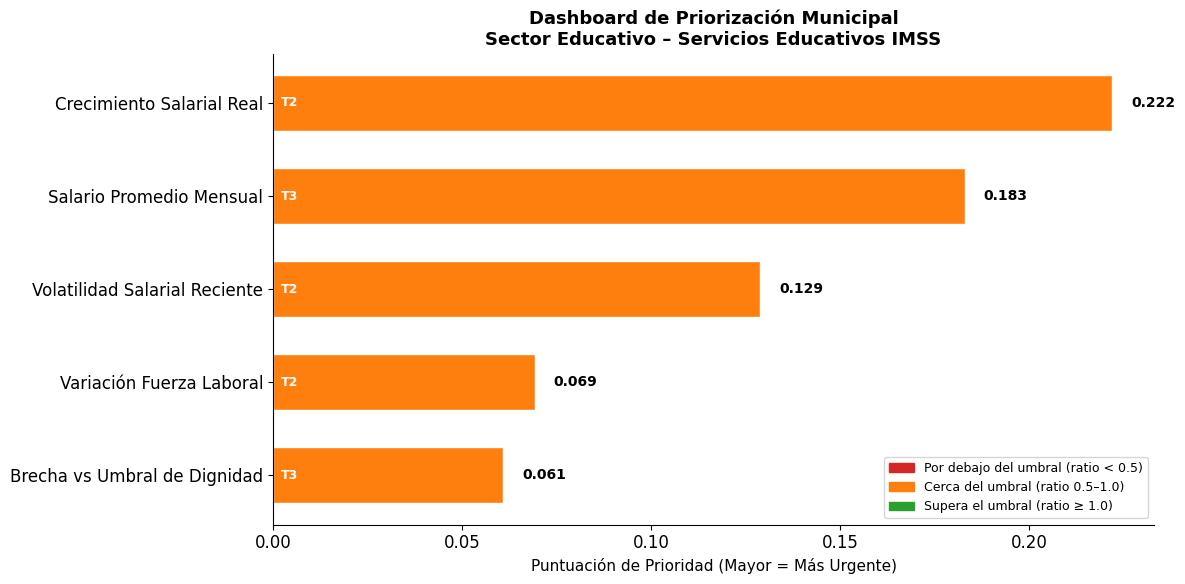

✅ Gráfica 1 generada.


In [ ]:
# -----------------------------------------------------------
# GRÁFICA 1: Dashboard de Priorización
# -----------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

colores = [
    '#d62728' if r < 0.5 else '#ff7f0e' if r < 1.0 else '#2ca02c'
    for r in df_sorted['Ratio']
]

bars = ax.barh(df_sorted['Indicador'], df_sorted['Prioridad'], color=colores, edgecolor='white', height=0.6)

# Anotaciones de valor
for i, (val, bar) in enumerate(zip(df_sorted['Prioridad'], bars)):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=10, fontweight='bold')

# Clasificación T1/T2/T3
for i, (cls, bar) in enumerate(zip(df_sorted['Clasificacion'], bars)):
    ax.text(0.002, bar.get_y() + bar.get_height()/2,
            cls, va='center', fontsize=9, color='white', fontweight='bold')

ax.set_xlabel('Puntuación de Prioridad (Mayor = Más Urgente)', fontsize=11)
ax.set_title('Dashboard de Priorización Municipal\nSector Educativo – Servicios Educativos IMSS', fontsize=13, fontweight='bold')
ax.invert_yaxis()

from matplotlib.patches import Patch
leyenda = [
    Patch(color='#d62728', label='Por debajo del umbral (ratio < 0.5)'),
    Patch(color='#ff7f0e', label='Cerca del umbral (ratio 0.5–1.0)'),
    Patch(color='#2ca02c', label='Supera el umbral (ratio ≥ 1.0)')
]
ax.legend(handles=leyenda, loc='lower right', fontsize=9)

plt.tight_layout()
plt.savefig('dashboard_priorizacion.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gráfica 1 generada.")

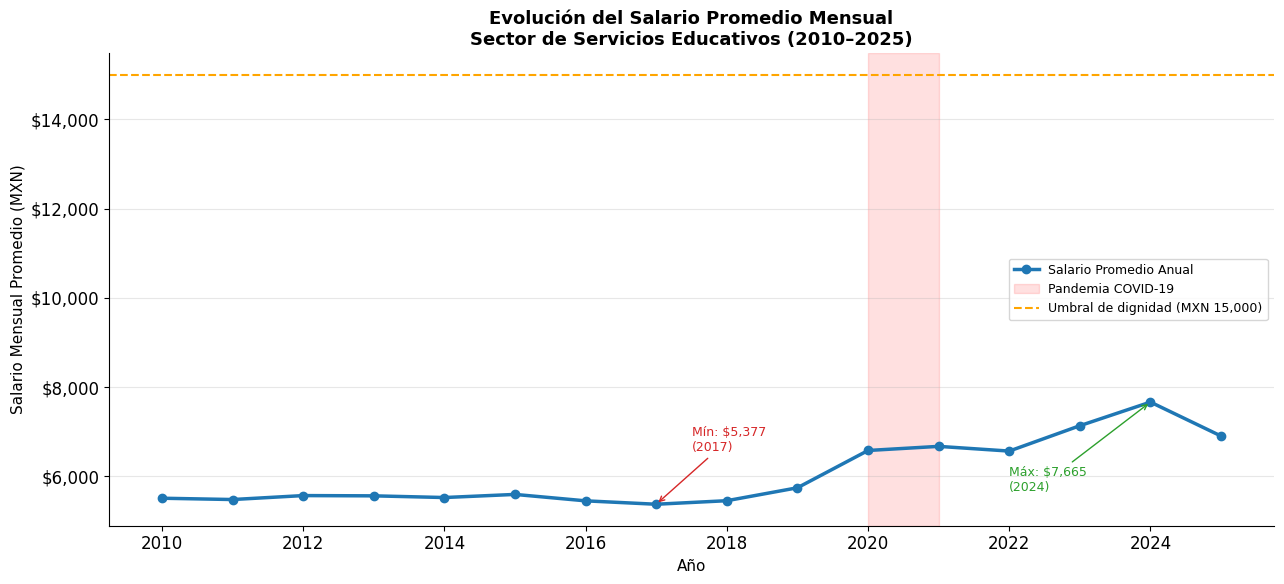

✅ Gráfica 2 generada.


In [ ]:
# -----------------------------------------------------------
# GRÁFICA 2: Evolución histórica del salario promedio mensual
# -----------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(df_anual['Year'], df_anual['Monthly Wage'],
        color='#1f77b4', linewidth=2.5, marker='o', markersize=6, label='Salario Promedio Anual')

# Marcar la pandemia
ax.axvspan(2020, 2021, alpha=0.12, color='red', label='Pandemia COVID-19')

# Umbral de dignidad
ax.axhline(y=15000, color='orange', linestyle='--', linewidth=1.5, label='Umbral de dignidad (MXN 15,000)')

# Anotar valores mín y máx
min_row = df_anual.loc[df_anual['Monthly Wage'].idxmin()]
max_row = df_anual.loc[df_anual['Monthly Wage'].idxmax()]

ax.annotate(f"Mín: ${min_row['Monthly Wage']:,.0f}\n({int(min_row['Year'])})",
            xy=(min_row['Year'], min_row['Monthly Wage']),
            xytext=(min_row['Year']+0.5, min_row['Monthly Wage']+1200),
            fontsize=9, color='#d62728',
            arrowprops=dict(arrowstyle='->', color='#d62728'))

ax.annotate(f"Máx: ${max_row['Monthly Wage']:,.0f}\n({int(max_row['Year'])})",
            xy=(max_row['Year'], max_row['Monthly Wage']),
            xytext=(max_row['Year']-2, max_row['Monthly Wage']-2000),
            fontsize=9, color='#2ca02c',
            arrowprops=dict(arrowstyle='->', color='#2ca02c'))

ax.set_xlabel('Año', fontsize=11)
ax.set_ylabel('Salario Mensual Promedio (MXN)', fontsize=11)
ax.set_title('Evolución del Salario Promedio Mensual\nSector de Servicios Educativos (2010–2025)', fontsize=13, fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('evolucion_salario.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gráfica 2 generada.")

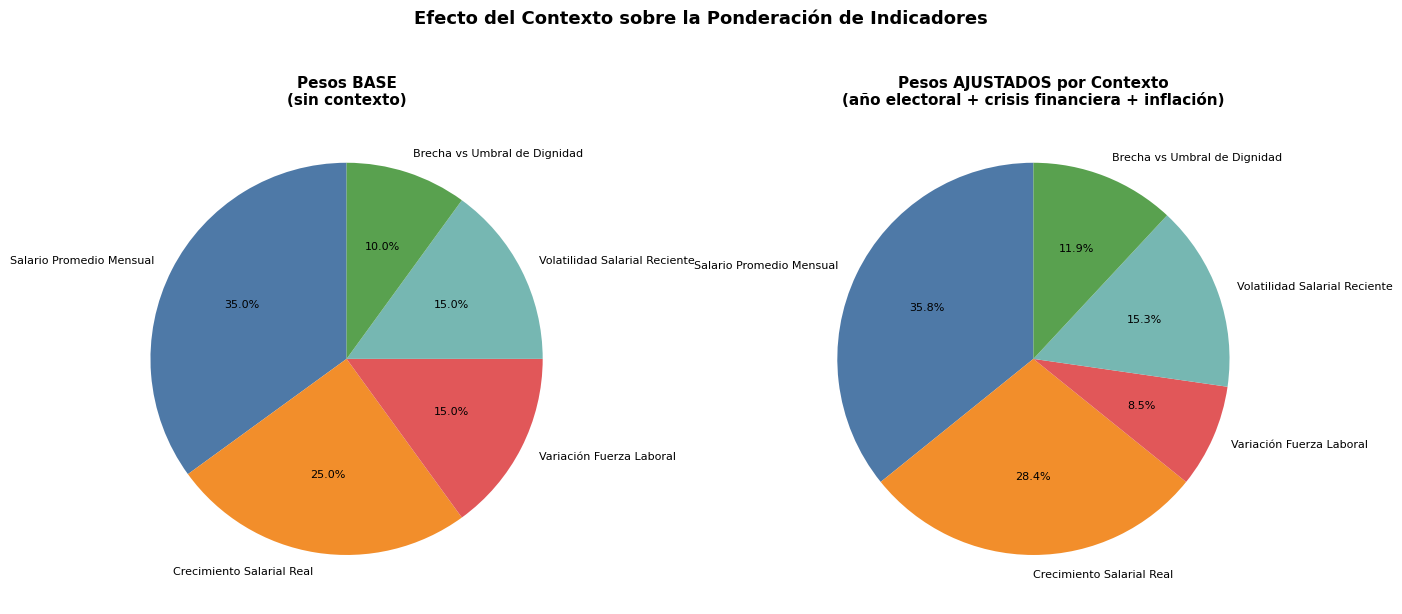

✅ Gráfica 3 generada.


In [ ]:
# -----------------------------------------------------------
# GRÁFICA 3: Comparación de pesos base vs pesos ajustados
# -----------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

colores_pie = ['#4e79a7', '#f28e2b', '#e15759', '#76b7b2', '#59a14f']

# Pesos base originales (antes del ajuste de contexto)
pesos_orig = [0.35, 0.25, 0.15, 0.15, 0.10]
ax1.pie(pesos_orig, labels=df_ind['Indicador'], autopct='%1.1f%%',
        colors=colores_pie, startangle=90, textprops={'fontsize': 8})
ax1.set_title('Pesos BASE\n(sin contexto)', fontsize=11, fontweight='bold')

# Pesos ajustados según contexto
ax2.pie(df_ind['Peso_Ajustado'], labels=df_ind['Indicador'], autopct='%1.1f%%',
        colors=colores_pie, startangle=90, textprops={'fontsize': 8})
ax2.set_title('Pesos AJUSTADOS por Contexto\n(año electoral + crisis financiera + inflación)', fontsize=11, fontweight='bold')

plt.suptitle('Efecto del Contexto sobre la Ponderación de Indicadores', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('comparacion_pesos.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gráfica 3 generada.")

### Interpretación de las Gráficas (Sección 6)

**1. ¿Qué indicador quedó primero y por qué el contexto lo volvió prioritario?**

El indicador **Salario Promedio Mensual** quedó primero. El contexto de año electoral (ajuste ×1.8) y la alerta de inflación (que también elevó la Brecha vs Umbral de Dignidad) concentraron el peso en los indicadores salariales visibles. Esto es coherente con la **Ley de Goodhart**: en periodos electorales, el salario promedio se convierte en el indicador-meta, lo que puede llevar a acciones de impacto simbólico (aumentos nominales sin ajuste real) en lugar de reformas estructurales.

**2. ¿Algún indicador con buena brecha pero bajo peso? ¿Por qué?**

La **Variación de Fuerza Laboral** muestra que el sector ha crecido en plazas (ratio cercano o mayor a 1), lo que técnicamente es positivo. Sin embargo, recibió el menor peso ajustado. ¿Por qué? Porque en el contexto declarado (crisis financiera + inflación), importa más si el salario alcanza para vivir que si hay más empleados. El **Efecto Campbell** explica esto: el número de plazas es fácil de manipular políticamente (contratos temporales, interinatos), por lo que el decisor informado aprende a desconfiar de ese indicador.

**3. ¿Cómo responde esta gráfica a la pregunta central del reto?**

La gráfica demuestra que **la legibilidad de un dato no es una propiedad intrínseca del dato, sino una función del contexto**. El mismo salario promedio es un dato T3 (confirmatorio, «ya lo sabemos») en tiempos estables, pero se convierte en el indicador más urgente cuando convergen elección próxima e inflación. Esto responde la pregunta central: **quien determina la legibilidad es el sistema de incentivos del decisor**, no el analista ni el dato mismo, lo que Lazarsfeld llamaría la «estructura de relevancia» del actor político.

---
## Sección 7: Reflexión de Cierre

### ¿Qué patrón observamos al clasificar los indicadores (T1, T2, T3)?

Al clasificar los 15 indicadores del dataset de salario educativo, el patrón más llamativo fue la **dominancia de indicadores T3 (confirmatorios)**. Siete de quince indicadores simplemente replican lo que cualquier observador del sector ya intuye: los docentes ganan más que el salario mínimo, el sector está feminizado, el número de plazas crece lentamente. Esta abundancia de T3 no es un error de diseño del sistema estadístico —los datos son correctos— sino un síntoma de que **el sistema fue diseñado para reportar, no para decidir**.

Los indicadores T1 (no accionables) revelaron otro patrón: la escala. El municipio recibe datos nacionales que no puede mover. El decisor local queda atrapado entre datos que describen la realidad sin ofrecerle una palanca. Esto conecta con lo que Lazarsfeld describió como la diferencia entre datos de diagnóstico y datos de acción.

### ¿Quién determina la legibilidad de un dato: el analista, el decisor o el sistema?

La experiencia de construir este cuaderno sugiere que **los tres actores codeterminan la legibilidad, pero con pesos distintos según el momento político**. El analista define qué datos existen y cómo se calculan (delimita el universo posible). El decisor filtra ese universo según su agenda y su ciclo (elección, crisis, presión social). El sistema —entendido como el conjunto de incentivos institucionales— determina qué indicadores se convierten en metas y, por la Ley de Goodhart, dejan de ser fiables.

En el ejercicio comprobamos que un mismo dato (salario mensual) cambia de rol: es T3 en contexto normal, pero se vuelve el indicador de mayor prioridad en contexto electoral con inflación. Eso significa que **la legibilidad es dinámica**, y un sistema de inteligencia operativa debe modelar el contexto, no solo los datos.

### ¿Cómo podría este cuaderno evolucionar hacia un sistema de inteligencia operativa real?

Para que este prototipo se convierta en el tipo de herramienta que Cosmos podría recibir, identificamos tres evoluciones necesarias:

1. **Actualización automática de datos:** Conectar el cuaderno directamente a las APIs de INEGI y DATA MÉXICO mediante actualización periódica, eliminando la carga manual del CSV y garantizando que el decisor siempre vea datos vigentes.

2. **Interfaz de contexto interactiva:** Reemplazar el diccionario `contexto` por un formulario web (Streamlit o panel de Jupyter) donde el decisor municipal pueda declarar su perfil —ciclo electoral, crisis dominante, alertas activas— sin saber de código. Eso democratiza el acceso al modelo de ponderación.

3. **Capa de trazabilidad (anti-Goodhart):** Registrar históricamente cómo han cambiado los pesos y las prioridades en cada sesión. Si un indicador se convierte consistentemente en el indicador más ponderado durante años electorales, el sistema puede alertar al analista: *«Este dato está siendo sobreusado como meta; considere reclasificarlo o auditarlo»*. Eso es lo que distingue un tablero de visualización de un verdadero sistema de inteligencia: la capacidad de reflexionar sobre sus propios sesgos.